In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.model_selection import train_test_split

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
# STEP 2: LOAD EMPLOYEE DATASET

import pandas as pd
from pathlib import Path

# Get project folder
PROJECT_DIR = Path.cwd()

# Employee CSV file
DATA_PATH = PROJECT_DIR / "employee.csv"

# Check and load dataset
if DATA_PATH.exists():

    df = pd.read_csv(DATA_PATH)

    print("Dataset loaded successfully!")

    print("\nFirst 5 Rows:")
    display(df.head())

    print("\nDataset Shape:")
    print(df.shape)

else:
    print("CSV file not found!")
    print("Expected location:", DATA_PATH)

Dataset loaded successfully!

First 5 Rows:


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2



Dataset Shape:
(1470, 35)


In [5]:
# STEP 3: DATA INSPECTION

# 1. Dataset information
print("DATASET INFORMATION")
print("-------------------")
df.info()

# 2. Dataset shape
print("\nDATASET SHAPE")
print(df.shape)

# 3. Column names
print("\nCOLUMN NAMES")
print(df.columns.tolist())

# 4. Missing values
print("\nMISSING VALUES")
print(df.isnull().sum())

# 5. Total missing values
print("\nTOTAL MISSING VALUES")
print(df.isnull().sum().sum())

# 6. Duplicate records
print("\nDUPLICATE RECORDS")
print(df.duplicated().sum())

# 7. Statistical summary
print("\nSTATISTICAL SUMMARY")
display(df.describe())

# 8. Target column balance
print("\nATTRITION CLASS BALANCE")
print(df["Attrition"].value_counts())

print("\nATTRITION PERCENTAGE")
print(df["Attrition"].value_counts(normalize=True) * 100)

DATASET INFORMATION
-------------------
<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EmployeeCount             1470 non-null   int64
 9   EmployeeNumber            1470 non-null   int64
 10  EnvironmentSatisfaction   1470 non-null   int64
 11  Gender                    1470 non-null   str  
 12  HourlyRate                1470 non-null   int64
 13  JobInvolvement            1470 non-null   int64
 14  JobLevel   

,Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,...,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,36.923810,802.485714,9.192517,2.912925,1.0,1024.865306,2.721769,65.891156,2.729932,2.063946,...,2.712245,80.0,0.793878,11.279592,2.799320,2.761224,7.008163,4.229252,2.187755,4.123129
std,9.135373,403.509100,8.106864,1.024165,0.0,602.024335,1.093082,20.329428,0.711561,1.106940,...,1.081209,0.0,0.852077,7.780782,1.289271,0.706476,6.126525,3.623137,3.222430,3.568136
min,18.000000,102.000000,1.000000,1.000000,1.0,1.000000,1.000000,30.000000,1.000000,1.000000,...,1.000000,80.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,465.000000,2.000000,2.000000,1.0,491.250000,2.000000,48.000000,2.000000,1.000000,...,2.000000,80.0,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,802.000000,7.000000,3.000000,1.0,1020.500000,3.000000,66.000000,3.000000,2.000000,...,3.000000,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,1157.000000,14.000000,4.000000,1.0,1555.750000,4.000000,83.750000,3.000000,3.000000,...,4.000000,80.0,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000
max,60.000000,1499.000000,29.000000,5.000000,1.0,2068.000000,4.000000,100.000000,4.000000,5.000000,...,4.000000,80.0,3.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000



ATTRITION CLASS BALANCE
Attrition
No     1233
Yes     237
Name: count, dtype: int64

ATTRITION PERCENTAGE
Attrition
No     83.877551
Yes    16.122449
Name: proportion, dtype: float64


In [6]:
# STEP 4: TRAIN-TEST SPLIT

from sklearn.model_selection import train_test_split

# Separate input features and target
X = df.drop("Attrition", axis=1)
y = df["Attrition"]

# Split dataset into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display dataset sizes
print("TRAIN-TEST SPLIT COMPLETED")

print("\nTraining Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target:", y_train.shape)
print("Testing Target:", y_test.shape)

print("\nTraining Attrition Balance:")
print(y_train.value_counts())

print("\nTesting Attrition Balance:")
print(y_test.value_counts())

TRAIN-TEST SPLIT COMPLETED

Training Features: (1176, 34)
Testing Features: (294, 34)

Training Target: (1176,)
Testing Target: (294,)

Training Attrition Balance:
Attrition
No     986
Yes    190
Name: count, dtype: int64

Testing Attrition Balance:
Attrition
No     247
Yes     47
Name: count, dtype: int64


In [15]:
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

# Project folder
PROJECT_DIR = Path.cwd()

if PROJECT_DIR.name != "churn_prediction":
    if (PROJECT_DIR / "churn_prediction").exists():
        PROJECT_DIR = PROJECT_DIR / "churn_prediction"

# Create EDA charts folder
CHART_DIR = PROJECT_DIR / "eda_charts"

CHART_DIR.mkdir(parents=True, exist_ok=True)

print("Project folder:", PROJECT_DIR)
print("Charts folder:", CHART_DIR)
print("Folder created successfully!")

Project folder: c:\Users\Admin\Desktop\python\.vscode\churn_prediction
Charts folder: c:\Users\Admin\Desktop\python\.vscode\churn_prediction\eda_charts
Folder created successfully!


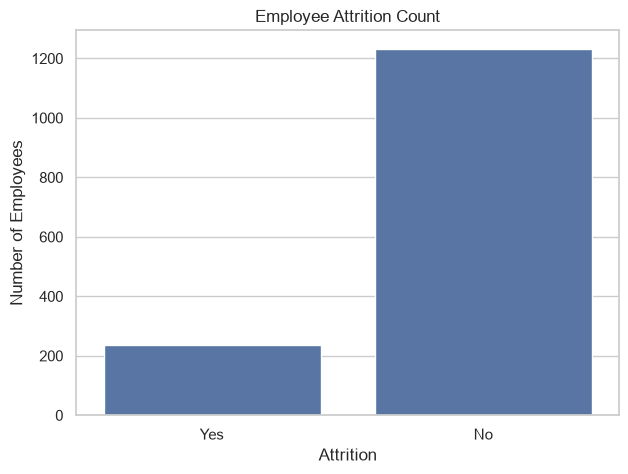

Chart 1 saved successfully!


In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

# Count employee attrition
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Attrition"
)

plt.title("Employee Attrition Count")
plt.xlabel("Attrition")
plt.ylabel("Number of Employees")

# Save chart
plt.savefig(CHART_DIR / "chart1_attrition_count.png")

plt.show()

print("Chart 1 saved successfully!")

In [22]:
# Step 9: Check Missing Values

print("Missing Values in Each Column:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())


# Check Duplicate Records

print("\nTotal Duplicate Rows:")
print(df.duplicated().sum())

print("\nDataset Information:")
print(df.info())

Missing Values in Each Column:
Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeNumber              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInCu

Attrition Class Count:
Attrition
No     1233
Yes     237
Name: count, dtype: int64

Attrition Class Percentage:
Attrition
No     83.877551
Yes    16.122449
Name: proportion, dtype: float64


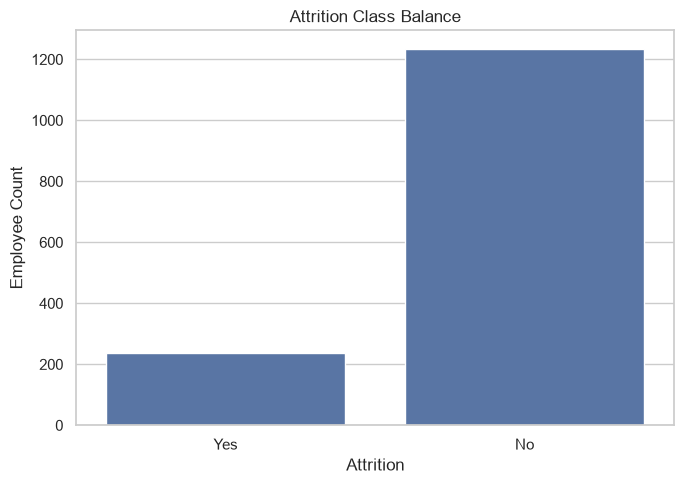

In [23]:
# Step 10: Check Class Balance

print("Attrition Class Count:")
print(df["Attrition"].value_counts())

print("\nAttrition Class Percentage:")
print(df["Attrition"].value_counts(normalize=True) * 100)

# Visualize class balance

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Attrition"
)

plt.title("Attrition Class Balance")
plt.xlabel("Attrition")
plt.ylabel("Employee Count")

plt.tight_layout()
plt.show()

In [24]:
from sklearn.model_selection import train_test_split

# Separate features and target
X = df.drop("Attrition", axis=1)
y = df["Attrition"]

# Split dataset into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display dataset sizes
print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training data shape: (1176, 34)
Testing data shape: (294, 34)
Training target shape: (1176,)
Testing target shape: (294,)


In [ ]:
from sklearn.model_selection import train_test_split

# Separate input features and target
X = df.drop("Attrition", axis=1)
y = df["Attrition"]

# Split 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("Training percentage:", len(X_train) / len(df) * 100)
print("Testing percentage:", len(X_test) / len(df) * 100)

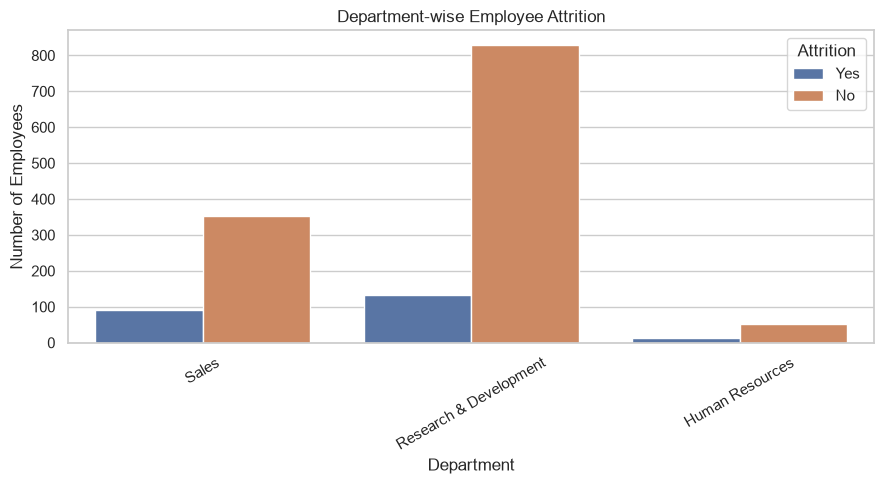

Chart 2 saved successfully!


In [25]:
# Chart 2: Department-wise Attrition

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Department",
    hue="Attrition"
)

plt.title("Department-wise Employee Attrition")
plt.xlabel("Department")
plt.ylabel("Number of Employees")
plt.xticks(rotation=30)

plt.tight_layout()

plt.savefig(CHART_DIR / "chart2_department_attrition.png")

plt.show()

print("Chart 2 saved successfully!")

In [ ]:
from sklearn.model_selection import train_test_split

# Separate input features and target
X = df.drop("Attrition", axis=1)
y = df["Attrition"]

# Split 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("Training percentage:", len(X_train) / len(df) * 100)
print("Testing percentage:", len(X_test) / len(df) * 100)

In [26]:
from sklearn.model_selection import train_test_split

# Separate input features and target
X = df.drop("Attrition", axis=1)
y = df["Attrition"]

# Split 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("Training percentage:", len(X_train) / len(df) * 100)
print("Testing percentage:", len(X_test) / len(df) * 100)

Training data: (1176, 34)
Testing data: (294, 34)
Training percentage: 80.0
Testing percentage: 20.0


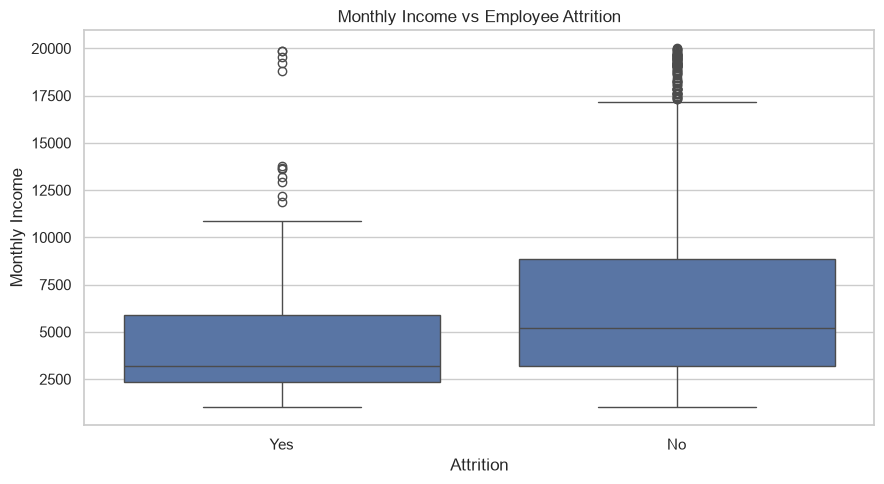

Chart 3 saved successfully!


In [18]:
# Chart 3: Monthly Income vs Attrition

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Attrition",
    y="MonthlyIncome"
)

plt.title("Monthly Income vs Employee Attrition")
plt.xlabel("Attrition")
plt.ylabel("Monthly Income")

plt.tight_layout()

plt.savefig(
    CHART_DIR / "chart3_monthly_income_attrition.png"
)

plt.show()

print("Chart 3 saved successfully!")

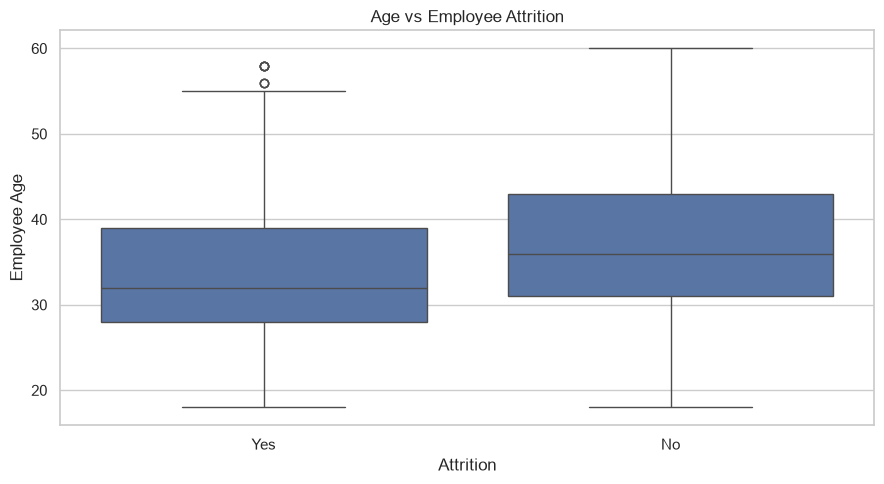

Chart 4 saved successfully!


In [19]:
# Chart 4: Age vs Attrition

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Attrition",
    y="Age"
)

plt.title("Age vs Employee Attrition")
plt.xlabel("Attrition")
plt.ylabel("Employee Age")

plt.tight_layout()

plt.savefig(
    CHART_DIR / "chart4_age_attrition.png"
)

plt.show()

print("Chart 4 saved successfully!")

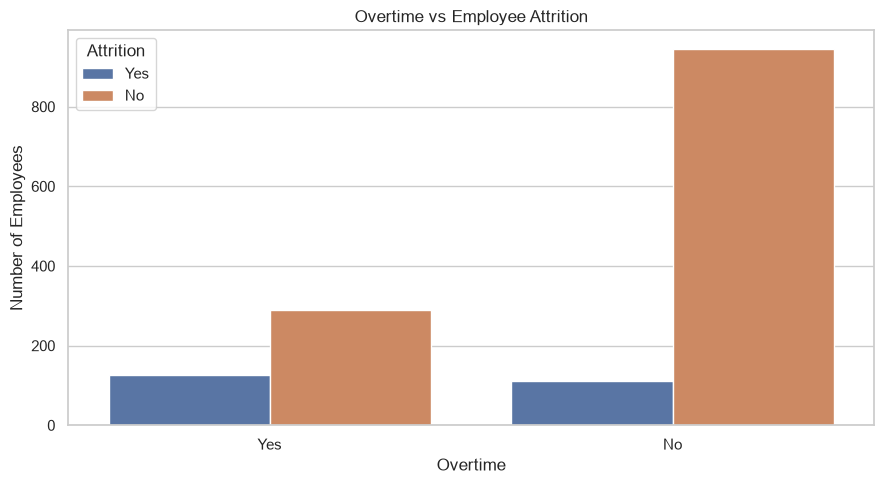

Chart 5 saved successfully!


In [20]:
# Chart 5: Overtime vs Attrition

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="OverTime",
    hue="Attrition"
)

plt.title("Overtime vs Employee Attrition")
plt.xlabel("Overtime")
plt.ylabel("Number of Employees")

plt.tight_layout()

plt.savefig(
    CHART_DIR / "chart5_overtime_attrition.png"
)

plt.show()

print("Chart 5 saved successfully!")

In [21]:
# Step 7: Train-Test Split

from sklearn.model_selection import train_test_split

# Separate input features and target
X = df.drop("Attrition", axis=1)
y = df["Attrition"]

# Split dataset into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display dataset sizes
print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

print("Train-test split completed successfully!")

Training data shape: (1176, 34)
Testing data shape: (294, 34)
Training target shape: (1176,)
Testing target shape: (294,)
Train-test split completed successfully!


Step 8: Project Assumptions and Metric Selection

1. Project Assumptions

1. The dataset contains employee information and an Attrition target column.
2. The target column contains two classes: Yes and No.
3. Missing values and duplicate records should be checked before model training.
4. Employee attributes such as Age, MonthlyIncome, Department and OverTime may influence employee attrition.
5. The dataset is assumed to represent historical employee records.
6. The test dataset (20%) will remain untouched until final model evaluation.

2. Evaluation Metric Selection

Selected Metric: F1-Score

F1-score is the harmonic mean of Precision and Recall.

It is suitable for this project because employee attrition datasets may have an imbalanced target, with fewer employees leaving than staying.

F1-score helps balance Precision and Recall and is useful for identifying employees who may leave the organization.

3. Conclusion

The project will use F1-score as the primary optimization metric. ROC-AUC will also be considered as a secondary evaluation metric.